# Marriage Duration and Astrological Signs of Couples

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from datetime import datetime as dt
from scipy import stats

# The Overall Data
There are a total of 4,374 entries in this dataset. 
Originally from the last project I have used this dataset, the dataset has 4,923 entries but 549 entries had one or two birthdates missing, therefore, are not going to be considered for this dataset and interpretation.

In [2]:
divorce = pd.read_csv("data_pandas.csv")
divorce.head()
divorce.info()

<class 'pandas.DataFrame'>
RangeIndex: 4374 entries, 0 to 4373
Data columns (total 50 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Divorce_date                          4374 non-null   str    
 1   Type_of_divorce                       4374 non-null   str    
 2   Nationality_partner_man               4374 non-null   str    
 3   DOB_partner_man                       4374 non-null   str    
 4   Place_of_birth_partner_man            4369 non-null   str    
 5   Birth_municipality_of_partner_man     4366 non-null   str    
 6   Birth_federal_partner_man             4367 non-null   str    
 7   Birth_country_partner_man             4368 non-null   str    
 8   Age_partner_man                       4374 non-null   float64
 9   Residence_municipality_partner_man    4238 non-null   str    
 10  Residence_federal_partner_man         4239 non-null   str    
 11  Residence_country_partner_ma

In [3]:
len(divorce)

4374

In [4]:
divorce[['Sign_Man','Sign_Woman','combo_couple']]

,Sign_Man,Sign_Woman,combo_couple
0,Sagittarius,Capicorn,"('Sagittarius', 'Capicorn')"
1,Pisces,Aires,"('Pisces', 'Aires')"
2,Scorpio,Libra,"('Scorpio', 'Libra')"
3,Aires,Gemini,"('Aires', 'Gemini')"
4,Sagittarius,Scorpio,"('Sagittarius', 'Scorpio')"
...,...,...,...
4369,Scorpio,Capicorn,"('Scorpio', 'Capicorn')"
4370,Scorpio,Aquarius,"('Scorpio', 'Aquarius')"
4371,Scorpio,Aquarius,"('Scorpio', 'Aquarius')"
4372,Aquarius,Aquarius,"('Aquarius', 'Aquarius')"


In [5]:
# Converting 'combo_couple' as a categorical variable
cols = divorce.select_dtypes(include=['object']).columns
divorce["combo_couple"] = divorce["combo_couple"].astype('category')

/var/folders/th/cy__chcj5wgbf_w94b8zbqsm0000gn/T/ipykernel_11738/806669291.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols = divorce.select_dtypes(include=['object']).columns


In [6]:
unique_astro_list = divorce['combo_couple'].cat.categories.tolist()

# Star Signs vs. Duration of Marriage
### Top 5 Longest Marriages and Top 5 Shortest Marriages
I have before created a column called `combo_couple`, which takes in both `Sign_Woman` and `Sign_Man`, this helps create more data points for each star sign duos and disregards gender.

In [7]:
all_mean=divorce.groupby("combo_couple")['Marriage_duration'].mean()
all_mean.sort_values(ascending=False)

combo_couple
('Pisces', 'Capicorn')            15.777778
('Libra', 'Pisces')               14.730769
('Sagittarius', 'Sagittarius')    14.264706
('Capicorn', 'Cancer')            14.095238
('Sagittarius', 'Pisces')         14.000000
                                    ...    
('Aires', 'Pisces')                7.937500
('Cancer', 'Capicorn')             7.900000
('Scorpio', 'Leo')                 7.846154
('Pisces', 'Aquarius')             7.828571
('Cancer', 'Virgo')                7.703704
Name: Marriage_duration, Length: 144, dtype: float64

In [8]:
all_med=divorce.groupby("combo_couple")['Marriage_duration'].median()
all_med.sort_values(ascending=False)

combo_couple
('Pisces', 'Capicorn')            14.0
('Capicorn', 'Cancer')            13.0
('Taurus', 'Scorpio')             13.0
('Sagittarius', 'Sagittarius')    13.0
('Cancer', 'Sagittarius')         12.5
                                  ... 
('Aquarius', 'Cancer')             6.0
('Pisces', 'Aquarius')             6.0
('Libra', 'Sagittarius')           5.5
('Sagittarius', 'Libra')           5.0
('Aires', 'Scorpio')               5.0
Name: Marriage_duration, Length: 144, dtype: float64

In [9]:
overall_mean=divorce['Marriage_duration'].mean()
overall_mean

np.float64(11.184086629001884)

## Pisces and Capicorn (Permuting the Median)
Pisces and Capicorn in the Divorce Data overall had the longest marriage duration based on mean and median. We are going to take a closer look at Pisces and Capicorn couples as there are a total of 144 categories. We are going to filter all Pisces and Capicorn data and create more data points by bootstrapping the data to see if the median marriage duration is relevent (as there is only 27 data points)

In [10]:
divorce_PC=divorce.copy()
Dicorce_P_C_filter=divorce_PC[divorce_PC['combo_couple']=="('Pisces', 'Capicorn')"]
non_div=divorce_PC[divorce_PC['combo_couple']!="('Pisces', 'Capicorn')"]
print(len(Dicorce_P_C_filter))

27


In [11]:
Dicorce_P_C_filter['Marriage_duration'].median()-non_div['Marriage_duration'].median()

np.float64(5.0)

In [12]:
Dicorce_P_C_filter[['Sign_Man','Sign_Woman','combo_couple','Marriage_duration']].head()

,Sign_Man,Sign_Woman,combo_couple,Marriage_duration
34,Pisces,Capicorn,"('Pisces', 'Capicorn')",23.0
140,Pisces,Capicorn,"('Pisces', 'Capicorn')",4.0
184,Pisces,Capicorn,"('Pisces', 'Capicorn')",4.0
421,Pisces,Capicorn,"('Pisces', 'Capicorn')",28.0
682,Pisces,Capicorn,"('Pisces', 'Capicorn')",29.0


Our observed value: Pisces and Capicorn couples in this dataset on average stays married for 15.78 years before divorce.

In [13]:
PC_Mean=Dicorce_P_C_filter['Marriage_duration'].median()
print(PC_Mean)

14.0


Histogram of the distribution of the original data before bootstrapping and years they stay married. The distribution shows a right skewed distribution.

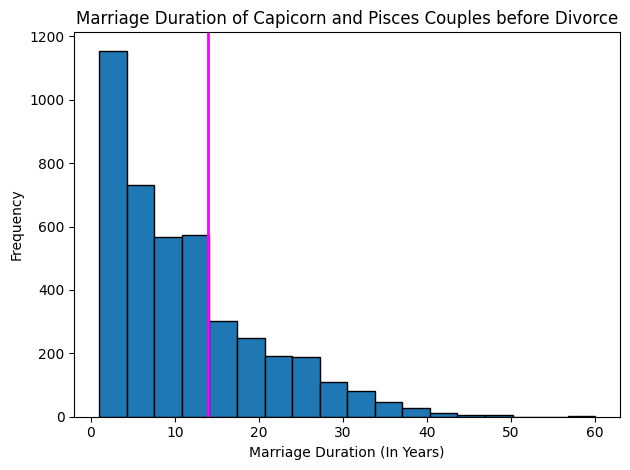

In [14]:
plt.hist(divorce_PC['Marriage_duration'], bins=18, edgecolor='black')
plt.axvline(PC_Mean, color='magenta', linestyle='-', linewidth=2)
plt.xlabel('Marriage Duration (In Years)')
plt.ylabel('Frequency')
plt.title('Marriage Duration of Capicorn and Pisces Couples before Divorce')
plt.tight_layout()
plt.show()

Replicating the observations 10,000 times with replacement.

In [15]:
replicates = []

for _ in range(10_000) : 
    replicates.append(divorce_PC[['combo_couple', 'Marriage_duration']].sample(frac=1, replace=True))

In [16]:
df_replicates = pd.concat(replicates, ignore_index=True)
Pis_Cap_filter_rep=df_replicates[df_replicates['combo_couple']=="('Pisces', 'Capicorn')"]
everythingelse_filter_rep=df_replicates[df_replicates['combo_couple']!="('Pisces', 'Capicorn')"]
diff_med_PC=Pis_Cap_filter_rep["Marriage_duration"].median()-everythingelse_filter_rep["Marriage_duration"].median()
print("difference in median of replicated data is",diff_med_PC,"years")

difference in median of replicated data is 5.0 years


The 95% confidence interval of marriage duration of the replicated data.

In [17]:
m = Pis_Cap_filter_rep["Marriage_duration"].mean()-everythingelse_filter_rep["Marriage_duration"].mean()
std_err = stats.sem(Pis_Cap_filter_rep["Marriage_duration"], nan_policy='omit')-stats.sem(everythingelse_filter_rep["Marriage_duration"], nan_policy='omit')
ci = stats.norm.interval(0.95, loc=m, scale=std_err)
print(f'The confidence interval of the shuffled data is between {ci[0]:.5f} and {ci[1]:.5f}')

The confidence interval of the shuffled data is between 4.57836 and 4.64213


Resampling the data 10,000 times from the replicated data. Takes a bit to run.

In [18]:
stored = [diff_med_PC]
gender_sim = divorce_PC['combo_couple'].tolist()

for _ in range(10000):
    np.random.shuffle(gender_sim)
    divorce_PC['combo_couple'] = gender_sim
    target_median = divorce_PC[divorce_PC['combo_couple'] == "('Pisces', 'Capicorn')"]['Marriage_duration'].median()
    others_median = divorce_PC[divorce_PC['combo_couple'] != "('Pisces', 'Capicorn')"]['Marriage_duration'].median()
    stored.append(target_median - others_median)

Plotting the histogram of the resampling. The orange lines is the confidence interval while the magenta line in the observed mean.

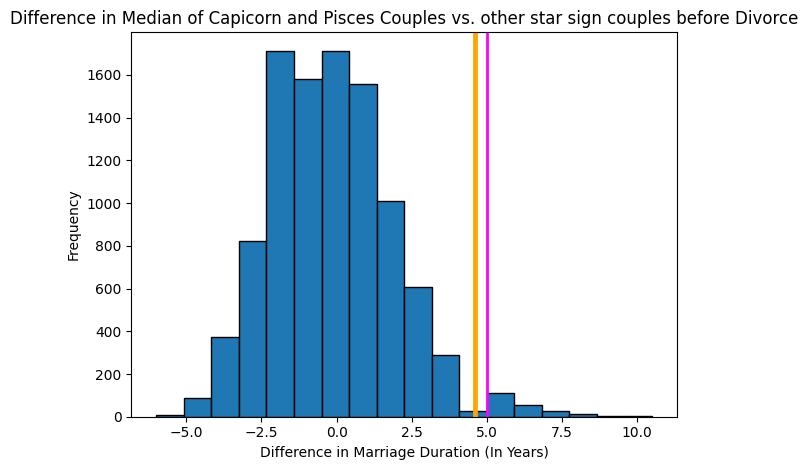

In [19]:
plt.hist(stored, bins=18, edgecolor='black')
plt.axvline(diff_med_PC, color='magenta', linestyle='-', linewidth=2)
plt.axvline(ci[0], color='orange', linestyle='-', linewidth=2)
plt.axvline(ci[1], color='orange', linestyle='-', linewidth=2)
plt.xlabel('Difference in Marriage Duration (In Years)')
plt.ylabel('Frequency')
plt.title('Difference in Median of Capicorn and Pisces Couples vs. other star sign couples before Divorce')
plt.tight_layout()
plt.show()

The P Value is less than 0.05, even more than 0.10. From the replicated data of Capicorn and Pisces couples, this shows there is a difference between Pisces and Capricorn couples. However, since we are using median, Central Limit Teorem does not apply and this result could have been a false positive.

In [20]:
replicates2=np.array(stored)
(abs(replicates2) >= abs(diff_med_PC)).mean()

np.float64(0.028397160283971604)

## Is there Literally Anything Else Statically Significant (based on mean)?
We found the P Value of Capicorn and Pisces Couples and how many years they stayed married providided  statiscal significance. Let's find out if the other star sign duos may provide statiscal significance based on difference on median overall.
Now using the smiliar functions, replication, and permutation methods from our investigation on Capicorn and Pisces Couples, we will apply it to all 144 categories except
Can the star signs of couples predict how long a couple will stay married?

In [21]:
divorce_copy = divorce.copy()
replicates2 = []
for _ in range(5): 
    replicates2.append(divorce_copy[['combo_couple', 'Marriage_duration']].sample(frac=1, replace=True))
df_replicates = pd.concat(replicates2, keys=range(5), names=['replicate_id', 'original_index'])
df_replicates = df_replicates.reset_index()


There are going to be more replicates of a total length of 21,870 rows.

In [22]:
len(df_replicates)

21870

In [23]:
#shuffle data of choice, a big list of a mess, no need to use on its own
def shuffle(choice):    
    gender_sim = df_replicates['combo_couple'].tolist()
    lister=[]
    for _ in range(999):
        np.random.shuffle(gender_sim)
        df_replicates['combo_couple'] = gender_sim
        overall_med=df_replicates['Marriage_duration'].median()
        sorted_median = df_replicates.groupby('combo_couple')["Marriage_duration"].median()
        part=sorted_median[choice]-overall_med
        lister.append(part)
    return lister

In [24]:
def calculation(list_ofchoice):
    replicates3=np.array(list_ofchoice)
    div_Mean=np.mean(list_ofchoice)
    rep_pval=(abs(replicates3) >= abs(div_Mean)).mean()
    return [div_Mean,rep_pval]

In [25]:
def another_row(star_sign):
    row=calculation(shuffle(star_sign))
    row.insert(0, star_sign)
    return row

In [26]:
s_col = ['Star Sign Duo', 'Median Differnce in Marriage Duration (yrs)', 'P Value']
Overview_astro = pd.DataFrame(columns=s_col)

Note: The function below will take longer to run as it is going through all 144 star signs

In [27]:
for i in unique_astro_list:
    new_row=another_row(i)
    Overview_astro.loc[len(Overview_astro)] = new_row

Star Sign Duos, Average Marriage Duration, and the P Value. It is sorted from smallest to largest P Value and shows the Top 5 smallest and Top 5 largest P Values.

In [28]:
Overview_astro.sort_values(by='P Value',ascending=True)

,Star Sign Duo,Median Differnce in Marriage Duration (yrs),P Value
78,"('Libra', 'Libra')",-0.356356,0.599600
139,"('Virgo', 'Pisces')",-0.439940,0.603604
107,"('Sagittarius', 'Virgo')",-0.386386,0.611612
25,"('Cancer', 'Aquarius')",-0.347347,0.613614
141,"('Virgo', 'Scorpio')",-0.368869,0.614615
...,...,...,...
113,"('Scorpio', 'Leo')",-0.346847,0.756757
98,"('Sagittarius', 'Cancer')",-0.344845,0.759760
42,"('Capicorn', 'Libra')",-0.215215,0.762763
50,"('Gemini', 'Cancer')",-0.328829,0.763764


Now the tables have turned...
The test being slightly different than previosuly done on just Pisces Couples (this time we doing overall median with the target star sign included due to efficiency).
The test did not provide a conclusion and we cannot reject  the null hypothesis because now we have p values ranging from 0.56 to 0.79.

# Is Age Just a Number?

Using a linear regression, is there a linear relationship between Age Gap and Marriage Duration?
We will first create a new columns called `Age_Diff` that will take the ages of both partners and subtract them (positive indicates the man partner is older versus negative indicates the woman partner is older). This test considers gender of the partners.

In [29]:
divorce2=divorce.copy()
divorce2['Age_Diff']=divorce2['Age_partner_man']-divorce2['Age_partner_woman']

Plotting the data points of marriage duration.

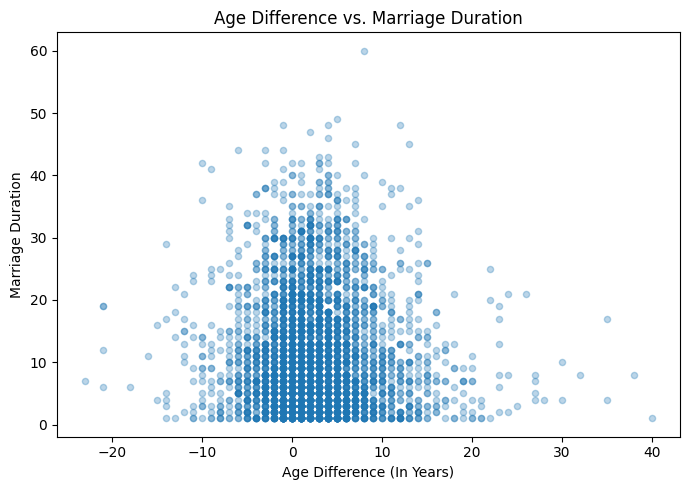

In [30]:
chosen_clean = divorce2.dropna(subset=['Age_Diff', 'Marriage_duration'])
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(chosen_clean['Age_Diff'], chosen_clean['Marriage_duration'], alpha=0.3, s=20)
ax.set_xlabel('Age Difference (In Years)')
ax.set_ylabel('Marriage Duration')
ax.set_title('Age Difference vs. Marriage Duration')
plt.tight_layout()
plt.show()

Seeing a description of the data. 
The mean being 2.37 age gap (men being older than women).
On average, couples were married for 11.19 years before divorce.

In [31]:
chosen_clean[['Age_Diff','Marriage_duration']].describe()

,Age_Diff,Marriage_duration
count,4247.000000,4247.000000
mean,2.370615,11.186249
std,5.230861,9.020776
min,-23.000000,1.000000
25%,0.000000,4.000000
50%,2.000000,9.000000
75%,5.000000,16.000000
max,40.000000,60.000000


Fitting a linear regression model.

In [32]:
results = smf.ols('Marriage_duration ~ Age_Diff', data=chosen_clean).fit()

In [33]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      Marriage_duration   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.975
Date:                Tue, 12 May 2026   Prob (F-statistic):              0.160
Time:                        17:38:21   Log-Likelihood:                -15366.
No. Observations:                4247   AIC:                         3.074e+04
Df Residuals:                    4245   BIC:                         3.075e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     11.2744      0.152     74.194      0.000      10.976      11.572
Age_Diff      -0.0372      0.026     -1.405      0.160      -0.089       0.015
==============================================================================
Omnibus:                      717.759   Durbin-Watson:                   1.982
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1148.574
Skew:                           1.163   Prob(JB):                    3.89e-250
Kurtosis:                       4.040   Cond. No.                         6.34
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

With R-Squared at 0, this shows a linear regression is not a good predictor in terms of estimating age gap with marriage duration. In addition, the F-statistic sits at 1.975 which indicates age gap is not the best predictor for estimating marriage duration. There P Value of 0.16. While it is smaller than the P Value of using astrological signs to predict marriage duration, there is still not enough evidence that Age Gap can predict marriage duration.

# The Concerning Data Points

From first observing the dataset, I have found a couple of observations where there was child marriages (a partner being under 18 when married). I wanted to see if Flagged Marriages (marriages where a partner was under 18 years old at marriage date and other partner being 2 years older) affects marriage duration.

I will drop observations where there is a missing ages of partners and missing marriage durations.

In [34]:
divorce2 = divorce2.dropna(subset=['Age_partner_man', 'Age_partner_woman','Marriage_duration'])
len(divorce2)

4247

A total of 127 observation got dropped

Now to create a variable to find how old a partner was at the time of marriage.

In [35]:
divorce2['Age_of_Marriage_Woman']=divorce2['Age_partner_woman']-divorce2['Marriage_duration']
divorce2['Age_of_Marriage_Man']=divorce2['Age_partner_man']-divorce2['Marriage_duration']

Flagging Couples, this considers gender.
- `Flagged_Woman` is when the woman partner was under 18 at time of marriage and the man partner is more than 2 years older than the woman partner.
- `Flagged_Man` is when the man partner was under 18 at time of marriage and the woman partner is more than 2 years older than the man partner.

In [36]:
divorce2['Flagged_Woman'] = (divorce2['Age_of_Marriage_Woman'] < 18) & (divorce2['Age_Diff'] > 2)
divorce2['Flagged_Man'] = (divorce2['Age_of_Marriage_Man'] < 18) & (divorce2['Age_Diff'] > 2)

There are 7 observations where `Flagged_Man` is True: the man partner was under 18 at time of marriage and the woman partner is more than 2 years older than the man partner

In [37]:
divorce2['Flagged_Man'].value_counts()

Flagged_Man
False    4240
True        7
Name: count, dtype: int64

There are 179 observations where `Flagged_Woman` is True: the woman partner was under 18 at time of marriage and the man partner is more than 2 years older than the woman partner

In [38]:
divorce2['Flagged_Woman'].value_counts()

Flagged_Woman
False    4068
True      179
Name: count, dtype: int64

We are going to take the median of couples that are flagged versus couples that are not flagged. We use the median as it does not consider outliers in the calculation.

In [39]:
def diff_med(data,column):
    diffy_mean=data.groupby(column)['Marriage_duration'].median()
    difference=diffy_mean[True]-diffy_mean[False]
    return difference

By median, `Flagged_Man` couples would be married for 22 years longer than non-flagged couples.

In [40]:
med_Man=diff_med(divorce2,"Flagged_Man")
med_Man

np.float64(22.0)

By median, `Flagged_Woman` couples would be married for 6 years longer than non-flagged couples.

In [41]:
med_Woman=diff_med(divorce2,"Flagged_Woman")
med_Woman

np.float64(6.0)

Now we are going to do a permutation test on `Flagged_Woman` couples if there is a difference between marriage duration of flagged couples versus non-flagged couples. We are going to do so without replicating the data.

In [42]:
for_sim=divorce2.copy()
stored=[med_Woman]
gender_sim=for_sim['Flagged_Woman'].tolist()

In [43]:
for _ in range(999):
    np.random.shuffle(gender_sim)
    for_sim['Flagged_Woman']=gender_sim
    diff=diff_med(for_sim,'Flagged_Woman')
    stored.append(diff)

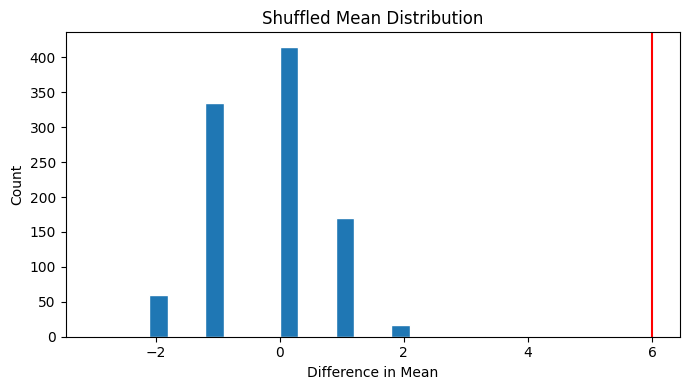

In [44]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(stored, bins=30, edgecolor='white')
ax.axvline(x=med_Woman,color="red")
ax.set_xlabel('Difference in Mean')
ax.set_ylabel('Count')
ax.set_title('Shuffled Mean Distribution')
plt.tight_layout()
plt.show()

In [45]:
stored_array=np.array(stored)
count_positive=(stored_array >= med_Woman).sum()
count_negative=(stored_array <= -1 * med_Woman).sum()
p_value=(count_positive+count_negative)/len(stored)
p_value

np.float64(0.001)

Now we are going to do a permutation test on `Flagged_Man` couples if there is a difference between marriage duration of flagged couples versus non-flagged couples. We are going to do so without replicating the data.

In [46]:
stored=[med_Man]
gender_sim=for_sim['Flagged_Man'].tolist()

In [47]:
for _ in range(999):
    np.random.shuffle(gender_sim)
    for_sim['Flagged_Man']=gender_sim
    diff=diff_med(for_sim,'Flagged_Man')
    stored.append(diff)

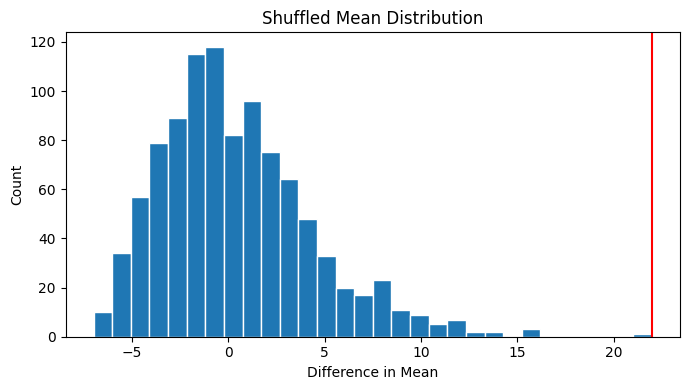

In [48]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(stored, bins=30, edgecolor='white')
ax.axvline(x=med_Man,color="red")
ax.set_xlabel('Difference in Mean')
ax.set_ylabel('Count')
ax.set_title('Shuffled Mean Distribution')
plt.tight_layout()
plt.show()

In [49]:
stored_array=np.array(stored)
count_positive=(stored_array >= med_Man).sum()
count_negative=(stored_array <= -1 * med_Man).sum()
p_value=(count_positive+count_negative)/len(stored)
print(p_value)

0.001


There is a strong relationship that marriage that involved grooming and child marriages (flagged) ended up lasting longer that marriage that did not involve grooming. There are more records of girls and women suseptable to grooming than men and boys.
This dataset does not account for couples that are still married or if a couple end up getting married later that one partner was groomed.